<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Momos20/si7011-catano/blob/main/evento2/sesion_03_6_integrador_eurosat.ipynb)


# SI7011 · Sesión 03 · Ejercicio integrador: ¿ImageNet sirve para mirar la Tierra desde el espacio?
**Juan David Martínez Vargas · Universidad EAFIT**

En los notebooks 1–5 cada pieza apareció sola: la CNN, BatchNorm, los residuales, la augmentation y el transfer learning; en este ejercicio se combinan sobre datos nuevos y cada corrida se registra en MLflow, siguiendo la misma lógica del integrador de la sesión 02.

**Datos: EuroSAT.** El conjunto contiene 27 000 imágenes del satélite Sentinel-2, de 64×64 píxeles en RGB, etiquetadas con **10 usos del suelo**, entre ellos cultivos, bosque, autopista, río, zona residencial y mar o lago; como son imágenes tomadas desde arriba, su dominio es diferente al de ImageNet.

| Etapa | Qué haces | Artefacto |
|---|---|---|
| Datos | validar el contrato, partir sin fuga y elegir una augmentation que respete el dominio (**TODO 1**) | `data_card.json` |
| Entrenamiento | definir el modelo (**TODO 2**) y el optimizador (**TODO 3**), además de registrar 3 corridas en MLflow | `best.pt` por corrida |
| Despliegue | predecir sobre imágenes crudas desde MLflow (**TODO 4**) | `predicciones.csv` |

**Entorno de trabajo:** Google Colab con GPU. El dataset se descarga automáticamente mediante `torchvision.datasets.EuroSAT`, por lo que no se requieren credenciales adicionales.


In [1]:
%pip install -q mlflow

In [2]:
import copy, hashlib, json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '· MLflow', mlflow.__version__, '· device', device)

PyTorch 2.11.0+cu130 · MLflow 3.17.2 · device cuda


## 1. Datos: contrato y ficha (listo)
El **contrato** dice qué acepta el modelo: imágenes RGB de 64×64 y una de las 10 clases. Se valida al cargar y se vuelve a validar al predecir. La **ficha** (*data card*) registra de dónde salieron los datos y se guarda con cada corrida.

In [3]:
def load_eurosat():
    print('Cargando EuroSAT con torchvision.datasets.EuroSAT')
    return datasets.EuroSAT('data', download=True), 'torchvision.datasets.EuroSAT'

ds, src = load_eurosat()
CLASSES = ds.classes
C = len(CLASSES)
CONTRACT = {'mode': 'RGB', 'size': [64, 64], 'classes': CLASSES}

# El mismo contrato se aplica al cargar los datos y al predecir (TODO 4)
def validate_image(img, contract=CONTRACT):
    if img.mode != contract['mode']:
        raise ValueError(f"Se esperaba una imagen {contract['mode']}, llegó {img.mode}.")
    if list(img.size) != contract['size']:
        raise ValueError(f"Se esperaba {contract['size']}, llegó {list(img.size)}.")
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

t0 = time.time()
X_all = torch.stack([validate_image(ds[i][0]) for i in range(len(ds))])
y_all = torch.tensor([label for _, label in ds.samples])
names = sorted(Path(p).name for p, _ in ds.samples)

data_card = {
    'fuente': src,
    'sha256_nombres': hashlib.sha256('\n'.join(names).encode()).hexdigest()[:16],
    'imagenes': len(ds),
    'clases': dict(zip(CLASSES, np.bincount(y_all, minlength=C).tolist()))
}

json.dump(data_card, open('data_card.json', 'w'), indent=1)
print(f'{len(X_all)} imágenes en {time.time() - t0:.0f} s')
data_card


Cargando EuroSAT con torchvision.datasets.EuroSAT


100%|██████████| 94.3M/94.3M [00:01<00:00, 79.2MB/s]


27000 imágenes en 14 s


{'fuente': 'torchvision.datasets.EuroSAT',
 'sha256_nombres': '41025a8d575789c1',
 'imagenes': 27000,
 'clases': {'AnnualCrop': 3000,
  'Forest': 3000,
  'HerbaceousVegetation': 3000,
  'Highway': 2500,
  'Industrial': 2500,
  'Pasture': 2000,
  'PermanentCrop': 2500,
  'Residential': 3000,
  'River': 2500,
  'SeaLake': 3000}}

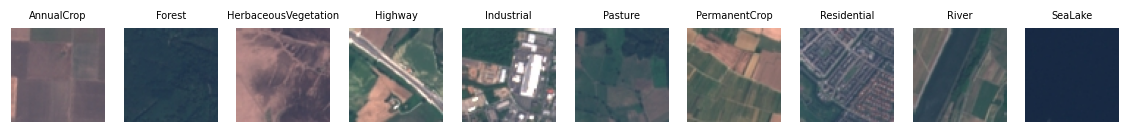

In [4]:
fig, axes = plt.subplots(1, C, figsize=(13, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(X_all[(y_all == c).nonzero()[0, 0]].permute(1, 2, 0)); ax.set_title(CLASSES[c], fontsize=6.5); ax.axis('off')
plt.show()

Las clases están casi balanceadas, pero no del todo. Reportamos la accuracy y también el **F1 macro**, como en Covertype.

La normalización es la de ImageNet para todos los modelos, también para el que se entrena desde cero, y viaja dentro de cada `best.pt`.

In [5]:
MEAN = ResNet18_Weights.IMAGENET1K_V1.transforms().mean
STD = ResNet18_Weights.IMAGENET1K_V1.transforms().std
_m, _s = torch.tensor(MEAN, device=device).view(1, 3, 1, 1), torch.tensor(STD, device=device).view(1, 3, 1, 1)
prep = lambda xb: (xb.to(device).float() / 255 - _m) / _s   # (x/255 − μ)/s con μ, s de ImageNet (notebook 4)

## 2. TODO 1 · Partición y augmentation · 10 min
1. Haz una partición **estratificada** 70/15/15 de los índices (entrenamiento/validación/prueba) con `random_state=0`. Si `TRAIN_SIZE` no es `None`, toma una submuestra de ese tamaño del entrenamiento.
2. Escribe `augment(xb)`: recibe un lote normalizado $N \times 3 \times 64 \times 64$ y devuelve uno del mismo tamaño. Elige transformaciones que **no cambien la clase de una imagen satelital**. Piensa en el *Tu turno* 3 del notebook 3: lo que estaba mal en CIFAR-10, ¿está mal aquí?

No hay estadísticas que calcular con entrenamiento: la normalización es fija. La fuga que hay que evitar aquí es que una misma imagen quede en dos particiones.

In [6]:
TRAIN_SIZE = None
idx_all = np.arange(len(y_all))

idx_train, idx_temp = train_test_split(
    idx_all,
    test_size=0.30,
    random_state=0,
    stratify=y_all.numpy()
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    random_state=0,
    stratify=y_all[idx_temp].numpy()
)

if TRAIN_SIZE is not None:
    idx_train, _ = train_test_split(
        idx_train,
        train_size=TRAIN_SIZE,
        random_state=0,
        stratify=y_all[idx_train].numpy()
    )

def augment(xb):
    xa = xb.clone()
    n = len(xa)

    # En imágenes satelitales la orientación absoluta no define la clase,
    # por eso se permiten rotaciones de 90° y flips horizontales/verticales.
    rotations = torch.randint(0, 4, (n,), device=xa.device)
    for k in (1, 2, 3):
        mask = rotations == k
        if mask.any():
            xa[mask] = torch.rot90(xa[mask], k=k, dims=(2, 3))

    hflip = torch.rand(n, device=xa.device) < 0.5
    vflip = torch.rand(n, device=xa.device) < 0.5

    if hflip.any():
        xa[hflip] = torch.flip(xa[hflip], dims=(3,))
    if vflip.any():
        xa[vflip] = torch.flip(xa[vflip], dims=(2,))

    return xa


entrenamiento 18900 · validación 4050 · prueba 4050


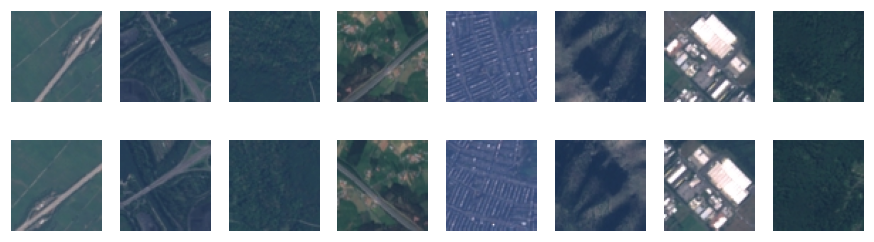

In [7]:
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
props = lambda idx: np.bincount(y_all[idx], minlength=C) / len(idx)
assert np.abs(props(idx_val) - props(idx_test)).max() < 0.01, 'Esperaba una partición estratificada.'
xb = prep(X_all[idx_train[:16]])
xa = augment(xb)
assert xa.shape == xb.shape, 'augment debe devolver un lote del mismo tamaño.'
assert not torch.allclose(xa, xb), 'augment no cambió nada.'
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
print('entrenamiento', len(y_train), '· validación', len(y_val), '· prueba', len(y_test))

show = lambda t: (t.cpu() * _s.cpu()[0] + _m.cpu()[0]).clamp(0, 1).permute(1, 2, 0)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for k in range(8):
    axes[0, k].imshow(show(xb[k])); axes[1, k].imshow(show(xa[k]))
for ax in axes.flat: ax.axis('off')
plt.show()

## 3. El loop y MLflow (listo)
`train_epoch` es el loop del notebook 3 con *scheduler* y la norma del gradiente. `run` hace lo mismo que en el integrador de la sesión 02:

- registra en **MLflow** los parámetros, las curvas por época, la pérdida inicial y la norma del gradiente;
- aplica **early stopping** sobre `val_loss`;
- guarda `best.pt` con los pesos **y** todo lo necesario para predecir: el nombre del constructor del modelo, la normalización y el contrato.

`before_epoch` permite, por ejemplo, congelar BatchNorm en cada época (notebook 4, sección 4).

In [8]:
loss_fn = nn.CrossEntropyLoss()  # L_i = −log softmax(f_θ(x_i))_{y_i}; recibe logits
BATCH = 128

def train_epoch(model, opt, scheduler=None, before_epoch=None):
    model.train()
    if before_epoch is not None:
        before_epoch(model)  # p. ej. freeze_bn (notebook 4, sección 4)
    perm = torch.randperm(len(y_train))
    total, norms = 0.0, []
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        # J_𝓑(θ) sobre el lote aumentado: tu augment del TODO 1, solo en entrenamiento (notebook 3, sección 3)
        loss = loss_fn(model(augment(prep(X_train[b]))), y_train[b].to(device))
        opt.zero_grad(); loss.backward()  # g_t = ∇_θ J_𝓑
        # ‖g_t‖ sin recortar (sesión 02, notebook 2, sección 6)
        norms.append(nn.utils.clip_grad_norm_(model.parameters(), float('inf')).item())
        opt.step()
        if scheduler is not None:
            scheduler.step()  # η_t = s(t) · η_0 en cada grupo (notebook 4, sección 4)
        total += loss.item() * len(b)
    return total / len(perm), float(np.mean(norms))

@torch.no_grad()
def evaluate(model, X, y, chunk=512):
    model.eval()  # Dropout apagado, BatchNorm con promedios móviles
    logits = torch.cat([model(prep(X[i:i + chunk])).float().cpu() for i in range(0, len(X), chunk)])
    pred = logits.argmax(1)
    return {'loss': loss_fn(logits, y).item(), 'acc': (pred == y).float().mean().item(),
            'macro_f1': f1_score(y, pred, average='macro', zero_division=0)}, pred.numpy()

In [9]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
EXPERIMENT = 'S03-eurosat'
mlflow.set_experiment(EXPERIMENT)

def run(name, build_model, make_opt, params, epochs=8, patience=3, before_epoch=None):
    torch.manual_seed(0)
    model = build_model().to(device)
    opt, scheduler = make_opt(model, epochs * math.ceil(len(y_train) / BATCH))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, 'epochs': epochs, 'patience': patience, 'train_size': len(y_train),
                           'n_params': sum(p.numel() for p in model.parameters()),
                           'n_trainable': sum(p.numel() for p in model.parameters() if p.requires_grad)})
        mlflow.log_dict(data_card, 'data_card.json')
        mlflow.log_metric('init_loss', evaluate(model, X_val, y_val)[0]['loss'])
        best, best_state, bad = {'val_loss': float('inf')}, None, 0
        for epoch in range(epochs):
            t0 = time.time()
            train_loss, grad_norm = train_epoch(model, opt, scheduler, before_epoch)
            va, _ = evaluate(model, X_val, y_val)
            row = {'train_loss': train_loss, 'grad_norm': grad_norm, 'lr': opt.param_groups[-1]['lr'],
                   'val_loss': va['loss'], 'val_acc': va['acc'], 'val_macro_f1': va['macro_f1'], 'epoch_s': time.time() - t0}
            if not math.isfinite(train_loss):
                mlflow.set_tag('status', 'diverged'); print('  diverge: se detiene'); break
            mlflow.log_metrics(row, step=epoch)
            # early stopping: θ* = argmin_t J_val(θ_t) (sesión 02, notebook 3, sección 4)
            if row['val_loss'] < best['val_loss']:
                best, best_state, bad = {**row, 'epoch': epoch}, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            if bad == patience:
                mlflow.set_tag('early_stopped', epoch); break
        print(f"{name}: mejor época {best.get('epoch')} · val_loss {best['val_loss']:.4f} · "
              f"val_acc {best.get('val_acc', 0):.3f} · F1 macro {best.get('val_macro_f1', 0):.3f}")
        if best_state is not None:
            mlflow.log_metrics({'best_epoch': best['epoch'], 'best_val_loss': best['val_loss'],
                                'best_val_acc': best['val_acc'], 'best_val_macro_f1': best['val_macro_f1']})
            # best.pt lleva todo lo necesario para predecir: constructor, θ*, normalización y contrato
            torch.save({'model': build_model.__name__, 'state_dict': best_state, 'mean': MEAN, 'std': STD,
                        'contract': CONTRACT}, 'best.pt')
            mlflow.log_artifact('best.pt')
    return model

2026/10/24 01:18:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/24 01:18:48 INFO mlflow.store.db.utils: Updating database tables
2026/10/24 01:18:50 INFO mlflow.tracking.fluent: Experiment with name 'S03-eurosat' does not exist. Creating a new experiment.


## 4. Corrida 1 · Línea base: una CNN desde cero (lista)
La red con bloques VGG y BatchNorm del notebook 3, con 32, 64 y 128 canales para imágenes de 64×64, se entrena desde cero con Adam.

**Predicción:** espero una accuracy de validación cercana a **0.75**, porque la CNN puede aprovechar la estructura espacial de EuroSAT; sin embargo, al partir desde cero y entrenarse solo durante ocho épocas, debería quedar por debajo de una estrategia que reutilice características de ImageNet.


In [10]:
# bloques VGG con BatchNorm del notebook 3, secciones 1–2, para entradas de 64×64
def baseline_model():
    def block(c_in, c_out):
        return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, C))

def baseline_opt(model, total_steps):
    return torch.optim.Adam(model.parameters(), lr=1e-3), None

print(f'ln 10 = {math.log(C):.3f}')
run('1-cnn-desde-cero', baseline_model, baseline_opt, {'estrategia': 'desde cero', 'arquitectura': 'VGG-BN 32-64-128', 'optimizador': 'Adam', 'lr': 1e-3});

ln 10 = 2.303
1-cnn-desde-cero: mejor época 6 · val_loss 0.1986 · val_acc 0.930 · F1 macro 0.927


## 5. TODO 2 · Tu modelo · 15 min
Se implementará `my_model()` para recibir imágenes de 3×64×64 y producir 10 salidas, usando una ResNet-18 con pesos de ImageNet y reemplazando únicamente la capa `fc`.

**Estrategia elegida:** *fine-tuning*. Aunque EuroSAT pertenece a un dominio diferente al de ImageNet, las primeras capas de una ResNet preentrenada ya contienen detectores útiles de bordes, texturas y formas; por eso se aprovechan esos pesos como punto de partida y, al mismo tiempo, se permite actualizar todo el backbone para adaptarlo progresivamente a las imágenes satelitales.


In [11]:
def my_model():
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, C)
    return model


In [12]:
torch.manual_seed(0)
m = my_model().to(device)
with torch.no_grad():
    m.eval(); init_loss = loss_fn(m(prep(X_val[:512])), y_val[:512].to(device)).item()
print(f'pérdida inicial {init_loss:.3f} (ln 10 = {math.log(C):.3f}) · entrenables {sum(p.numel() for p in m.parameters() if p.requires_grad):,}')
assert init_loss < 3 * math.log(C), 'La pérdida inicial está muy lejos de ln C: revisa la cabeza nueva.'

xb, yb = prep(X_train[:32]), y_train[:32].to(device)
opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3); m.train()
for _ in range(150):
    loss = loss_fn(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
print(f'sobreajustar 32 ejemplos: pérdida {loss.item():.4f}')
assert loss.item() < 0.1, 'El modelo no sobreajusta un lote: hay un error en el modelo.'

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


pérdida inicial 2.762 (ln 10 = 2.303) · entrenables 11,181,642
sobreajustar 32 ejemplos: pérdida 0.0000


## 6. TODO 3 · Tu optimizador · 10 min
Escribe `my_opt(model, total_steps)` y que devuelva `(optimizador, scheduler)`:

- `torch.optim.AdamW` con **dos grupos de parámetros**: la cabeza `fc` con un $\eta$ mayor y el resto con uno menor (notebook 4, sección 4). Si tu modelo congela el backbone, el grupo del backbone queda vacío o sus parámetros no se mueven, y está bien;
- *warmup* lineal de **1 época** y decaimiento coseno (`warmup_cosine` del notebook 4). Hay `math.ceil(len(y_train) / BATCH)` pasos por época.

Después, en la celda de la corrida, escribe en `params` lo que elegiste y decide si usas `before_epoch=freeze_bn`.

In [13]:
def freeze_bn(model):
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()

def my_opt(model, total_steps):
    lr_backbone = 1e-4
    lr_head = 1e-3
    weight_decay = 1e-4

    backbone_params = [
        p for name, p in model.named_parameters()
        if not name.startswith('fc.')
    ]
    head_params = list(model.fc.parameters())

    optimizer = torch.optim.AdamW(
        [
            {'params': backbone_params, 'lr': lr_backbone},
            {'params': head_params, 'lr': lr_head}
        ],
        weight_decay=weight_decay
    )

    warmup_steps = math.ceil(len(y_train) / BATCH)

    def schedule(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps

        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=schedule
    )

    return optimizer, scheduler


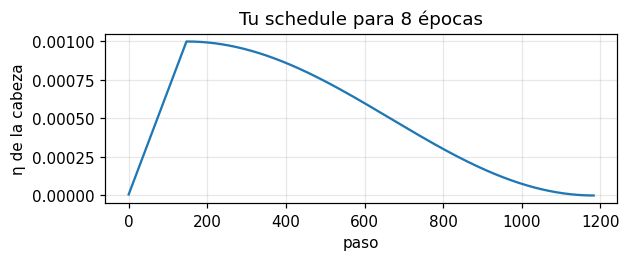

In [14]:
steps_per_epoch = math.ceil(len(y_train) / BATCH)
_m_ = my_model()
_opt, _sched = my_opt(_m_, 8 * steps_per_epoch)
assert isinstance(_opt, torch.optim.AdamW) and len(_opt.param_groups) == 2, 'Esperaba AdamW con dos grupos.'
lr_fc = [g['lr'] for g in _opt.param_groups if any(p is _m_.fc.weight for p in g['params'])]
lr_rest = [g['lr'] for g in _opt.param_groups if not any(p is _m_.fc.weight for p in g['params'])]
assert lr_fc and lr_rest and lr_fc[0] > lr_rest[0], 'La cabeza debe tener un η mayor que el backbone.'
lrs = []
for _ in range(8 * steps_per_epoch):
    lrs.append(_opt.param_groups[-1]['lr']); _opt.step(); _sched.step()
peak = int(np.argmax(lrs))
assert lrs[0] <= 1.5 * max(lrs) / steps_per_epoch and abs(peak - steps_per_epoch) <= 2, 'Esperaba warmup lineal durante la primera época.'
assert lrs[-1] < 0.01 * max(lrs), 'Esperaba que η llegara casi a cero al final.'
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.xlabel('paso'); plt.ylabel('η de la cabeza'); plt.title('Tu schedule para 8 épocas'); plt.show()

In [15]:
params = {
    'estrategia': 'fine-tuning',
    'arquitectura': 'resnet18 ImageNet',
    'optimizador': 'AdamW',
    'lr_backbone': 1e-4,
    'lr_cabeza': 1e-3,
    'weight_decay': 1e-4,
    'schedule': 'warmup 1 época + coseno',
    'augment': 'rotaciones 90° + flip horizontal + flip vertical',
    'freeze_bn': False
}

run(
    '2-mi-receta',
    my_model,
    my_opt,
    params,
    before_epoch=None
)


2-mi-receta: mejor época 6 · val_loss 0.0738 · val_acc 0.978 · F1 macro 0.977


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## 7. Corrida 3 · Cambia una sola cosa · 5 min
En esta corrida se mantiene exactamente la misma arquitectura, inicialización, augmentation, optimizador, learning rates, weight decay y schedule; el único cambio consiste en congelar BatchNorm durante el entrenamiento mediante `freeze_bn`.

**Predicción:** espero una ligera reducción del desempeño, porque EuroSAT tiene una distribución visual distinta a ImageNet y permitir que BatchNorm actualice sus estadísticas puede ayudar a adaptar mejor la red al nuevo dominio; aun así, la diferencia podría ser pequeña porque los pesos preentrenados ya ofrecen un buen punto de partida.


In [16]:
params_3 = params.copy()
params_3.update({
    'freeze_bn': True,
    'cambio': 'congelar BatchNorm',
    'prediccion': 'ligera reducción del desempeño'
})

run(
    '3-freeze-bn',
    my_model,
    my_opt,
    params_3,
    before_epoch=freeze_bn
)


3-freeze-bn: mejor época 6 · val_loss 0.0718 · val_acc 0.976 · F1 macro 0.975


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## 8. Comparar en MLflow (listo)

In [17]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=['attributes.start_time ASC'])
runs = runs.drop_duplicates('tags.mlflow.runName', keep='last').set_index('tags.mlflow.runName')
cols = ['params.n_trainable', 'metrics.init_loss', 'metrics.best_epoch', 'metrics.best_val_loss', 'metrics.best_val_acc', 'metrics.best_val_macro_f1']
runs[cols].round(3)

,params.n_trainable,metrics.init_loss,metrics.best_epoch,metrics.best_val_loss,metrics.best_val_acc,metrics.best_val_macro_f1
tags.mlflow.runName,,,,,,
1-cnn-desde-cero,288746,2.304,6.0,0.199,0.930,0.927
2-mi-receta,11181642,2.716,6.0,0.074,0.978,0.977
3-freeze-bn,11181642,2.716,6.0,0.072,0.976,0.975


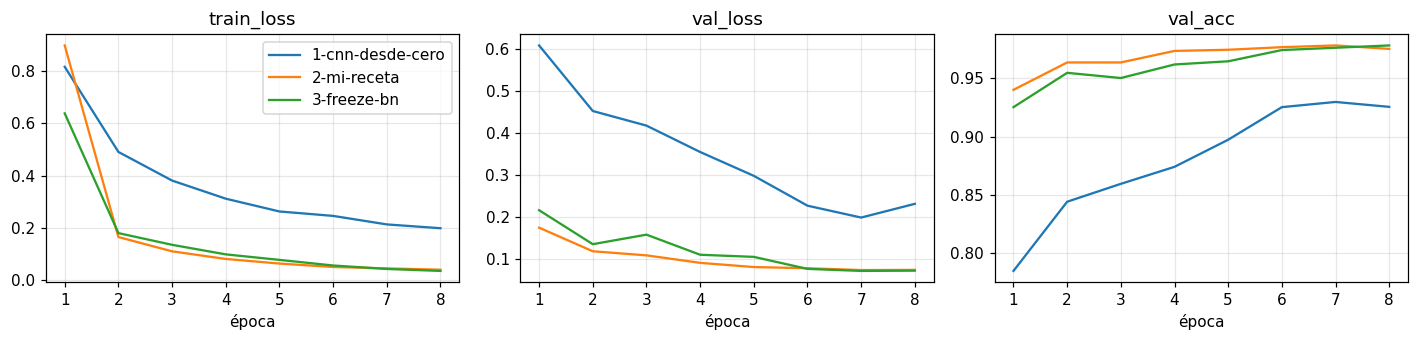

In [18]:
client = mlflow.MlflowClient()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name, r in runs.iterrows():
    for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
        hist = client.get_metric_history(r.run_id, key)
        ax.plot([m.step + 1 for m in hist], [m.value for m in hist], label=name)
for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
    ax.set(title=key, xlabel='época')
axes[0].legend(); fig.tight_layout(); plt.show()

**Opcional · interfaz web.** Si después quieres inspeccionar las corridas con la interfaz de MLflow, puedes descargar `mlflow.db` y `mlruns/` desde Colab y abrirlos localmente con `mlflow ui --backend-store-uri sqlite:///mlflow.db`.


## 9. Evaluar en prueba una sola vez (listo)
Se elige la corrida por `best_val_loss`, **nunca** por la prueba, y se carga su `best.pt` **desde MLflow**.

In [19]:
chosen = runs.sort_values('metrics.best_val_loss').iloc[0]
print('Corrida elegida:', chosen.name)
ckpt = torch.load(mlflow.artifacts.download_artifacts(run_id=chosen.run_id, artifact_path='best.pt'), map_location='cpu', weights_only=False)
BUILDERS = {f.__name__: f for f in [baseline_model, my_model] + [v for v in globals().values() if callable(v) and getattr(v, '__name__', '').endswith('_model')]}
model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.to(device).eval()
test_metrics, pred_test = evaluate(model, X_test, y_test)
with mlflow.start_run(run_id=chosen.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
print({k: round(v, 4) for k, v in test_metrics.items()})

Corrida elegida: 3-freeze-bn


{'loss': 0.0922, 'acc': 0.9701, 'macro_f1': 0.9691}


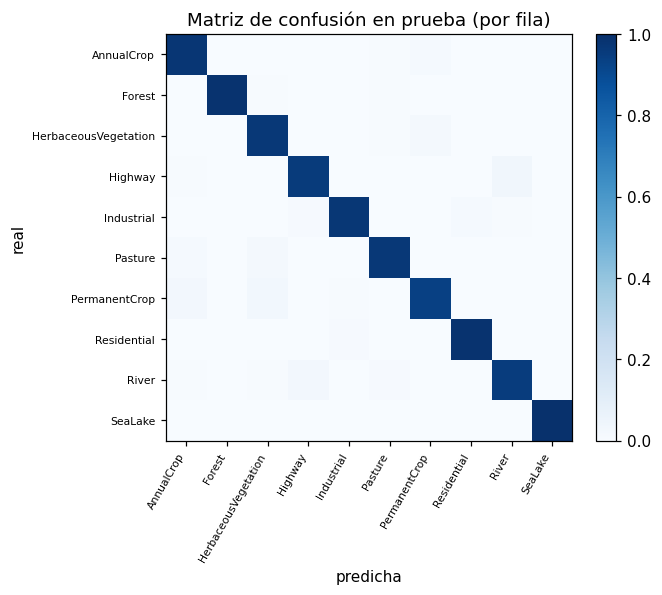

In [20]:
cm = confusion_matrix(y_test, pred_test, normalize='true')
plt.figure(figsize=(5.5, 4.8)); plt.imshow(cm, cmap='Blues', vmin=0, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(C), CLASSES, rotation=60, ha='right', fontsize=7); plt.yticks(range(C), CLASSES, fontsize=7)
plt.xlabel('predicha'); plt.ylabel('real'); plt.title('Matriz de confusión en prueba (por fila)'); plt.grid(False); plt.show()

## 10. TODO 4 · Despliegue: predecir sobre imágenes crudas · 10 min
Escribe `predict_raw(ckpt, images)`. Recibe una **lista de imágenes PIL**, como las que llegarían de un usuario, y devuelve un `DataFrame` con `clase` (el nombre) y `confianza`. Usa solo lo que trae `ckpt`:

1. `validate_image(img, ckpt['contract'])` para cada imagen, y apilar;
2. normalizar con `ckpt['mean']` y `ckpt['std']`;
3. reconstruir el modelo con `BUILDERS[ckpt['model']]()`, cargar los pesos y ponerlo en `eval()`;
4. aplicar softmax y elegir la clase.

In [21]:
@torch.no_grad()
def predict_raw(ckpt, images):
    X = torch.stack([
        validate_image(img, ckpt['contract'])
        for img in images
    ]).float() / 255.0

    mean = torch.tensor(ckpt['mean']).view(1, 3, 1, 1)
    std = torch.tensor(ckpt['std']).view(1, 3, 1, 1)
    X = (X - mean) / std

    model = BUILDERS[ckpt['model']]()
    model.load_state_dict(ckpt['state_dict'])
    model.eval()

    probs = torch.softmax(model(X), dim=1)
    confidence, pred = probs.max(dim=1)

    classes = ckpt['contract']['classes']

    return pd.DataFrame({
        'clase': [classes[i] for i in pred.tolist()],
        'confianza': confidence.tolist()
    })


In [22]:
to_pil = transforms.ToPILImage()
raw_test = [to_pil(x) for x in X_test]                          # imágenes crudas de prueba, como PIL

out = predict_raw(ckpt, raw_test)
agree = (out['clase'].map(CLASSES.index).to_numpy() == pred_test).mean()
print(f'1. Consistencia con la evaluación de prueba: {agree:.2%}')
assert agree > 0.999, 'El artefacto no reproduce las predicciones: ¿falta eval() o la normalización?'

for bad in [raw_test[0].convert('L'), raw_test[0].resize((32, 32))]:
    try:
        predict_raw(ckpt, [bad]); raise AssertionError('Una imagen inválida debió ser rechazada.')
    except ValueError as e:
        print('2. Contrato: imagen rechazada →', e)

pd.concat([pd.DataFrame({'real': [CLASSES[i] for i in y_test[:1000]]}), out.head(1000)], axis=1).to_csv('predicciones.csv', index=False)
print('3. predicciones.csv escrito'); out.head()

1. Consistencia con la evaluación de prueba: 100.00%
2. Contrato: imagen rechazada → Se esperaba una imagen RGB, llegó L.
2. Contrato: imagen rechazada → Se esperaba [64, 64], llegó [32, 32].
3. predicciones.csv escrito


,clase,confianza
0,Pasture,0.999983
1,Residential,0.999997
2,AnnualCrop,0.999996
3,HerbaceousVegetation,0.954489
4,HerbaceousVegetation,0.997540


## 11. Preguntas y entrega

1. ¿Se cumplió tu predicción para la línea base? ¿Qué número del registro de MLflow lo muestra?
2. ¿Ayudó ImageNet con imágenes satelitales? Compara la línea base con tu receta en `best_val_acc` **y** en `n_trainable`.
3. ¿Qué transformaciones pusiste en `augment` y por qué no cambian la clase en EuroSAT? ¿Cuál de ellas estaría mal en CIFAR-10?
4. Mira la matriz de confusión: ¿qué pares de clases se confunden más? ¿Te parece razonable viendo las imágenes?
5. ¿Qué pasaría en producción si alguien enviara imágenes de 128×128 de otro satélite? ¿Qué hace hoy `predict_raw` y qué debería hacer?

_Respuestas:_

**1.** La predicción no se cumplió exactamente, porque esperaba una accuracy de validación cercana a **0.75** y la línea base alcanzó un `best_val_acc` de **0.930** en MLflow; por lo tanto, la CNN entrenada desde cero rindió bastante mejor de lo anticipado, aunque todavía quedó por debajo de las estrategias basadas en ResNet-18.

**2.** En esta comparación, ImageNet sí aportó una mejora importante, ya que la línea base obtuvo un `best_val_acc` de **0.930** con **288 746** parámetros entrenables, mientras que la receta con fine-tuning alcanzó **0.978** con **11 181 642** parámetros entrenables; por consiguiente, reutilizar representaciones preentrenadas y adaptarlas al dominio satelital produjo un mejor desempeño, aunque la comparación también implica una arquitectura de mayor capacidad y no permite atribuir toda la mejora únicamente al preentrenamiento.

**3.** En `augment` se usaron rotaciones de **90°**, flip horizontal y flip vertical, porque en EuroSAT la orientación absoluta de la escena no define el uso del suelo y esas transformaciones conservan su significado; en cambio, un flip vertical sería poco apropiado en CIFAR-10, ya que puede producir objetos con orientaciones poco naturales y alterar la semántica visual de fotografías convencionales.

**4.** La matriz de confusión muestra que una de las confusiones más marcadas ocurre entre **Highway y River**, mientras que también aparecen errores entre **PermanentCrop y HerbaceousVegetation**, además de algunos casos entre **PermanentCrop y AnnualCrop**; esto resulta razonable porque carreteras y ríos pueden aparecer como estructuras lineales vistas desde arriba, mientras que los distintos tipos de cobertura vegetal comparten colores, texturas y patrones espaciales similares.

**5.** Si llega una imagen de **128×128**, `predict_raw` la rechaza actualmente porque `validate_image` exige imágenes RGB de **64×64**, lo cual protege el contrato de entrada y evita predicciones silenciosamente inconsistentes; sin embargo, si se quisiera aceptar otro tamaño habría que incorporar un redimensionamiento explícito y, si además las imágenes provienen de otro satélite, también sería necesario validar el cambio de dominio, porque el sensor puede modificar resolución espacial, bandas, colores y distribución de los datos antes de considerar el modelo apto para producción.

**Entrega (evento evaluativo 2, Parte B):** notebook ejecutado con las salidas visibles, los 4 TODO resueltos y las cinco respuestas sustentadas con los resultados de las corridas, guardado en `evento2/sesion_03_6_integrador_eurosat.ipynb` dentro del repositorio del curso.